# Grayscale validation

Compare the existing grayscale conversion against an untreated baseline on the exact same 100 IAM and 100 Bentham validation lines as the denoising, deskew and CLAHE studies (seed 42). Restore dataset revision, checkpoint revision, generation options, batch size and source indices from the completed denoising metadata. No training or test evaluation.

Unlike the other techniques, `Grayscale` has only an enabled flag: there are no strengths, windows or other numeric parameters to tune. There is therefore one meaningful grayscale configuration, plus baseline, rather than five repetitions presented as different configurations. `grayscale` is Pillow's standard 8-bit luminance conversion. IAM is already L, so grayscale should leave its pixels and predictions unchanged; the final cell verifies that control.

Bentham RGBA is composited onto white RGB consistently for baseline and grayscale. Grayscale then removes color; TrOCR's mandatory RGB conversion replicates the resulting luminance into three channels. Original images and transcriptions stay unchanged. No denoising, deskew or CLAHE is applied. Whitespace is collapsed; case and punctuation retained. Rank by equal-dataset mean corpus CER, with WER breaking ties and baseline eligible. IAM is within TrOCR's training domain; Bentham is historical handwriting.

Results and batch checkpoints are under results/validation/grayscale/<UTC study ID>/. Rerun only the evaluation cell to resume within this session. These are subset-validation findings; confirm on validation data before freezing final test parameters.

In [1]:
import sys
from pathlib import Path
import json
import random
from datetime import datetime, timezone
from importlib.metadata import version
import numpy as np
import torch

ROOT = next(p for p in (Path.cwd(), *Path.cwd().parents) if (p / 'src/load_dataset/iam.py').exists())
sys.path.insert(0, str(ROOT))
from src.load_dataset.iam import load_iam_dataset
from src.load_dataset.bentham import load_bentham_dataset, REVISION, ARCHIVES
from src.models.trocr import TrOCRRecognizer
from src.validation.grayscale import configurations, evaluate, summarize

# Explicit reference pins this comparison to the completed denoising study.
REFERENCE = ROOT / 'results/validation/denoising/20261112T000633091905Z/metadata.json'
reference = json.loads(REFERENCE.read_text())
SEED = reference['seed']
BATCH_SIZE = reference['batch_size']
indices = reference['sample_indices']
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
assert reference['bentham_revision'] == REVISION
full_iam = load_iam_dataset('validation', revision=reference['iam_revision'])
full_bentham = load_bentham_dataset('validation')
assert {'iam': len(full_iam), 'bentham': len(full_bentham)} == reference['full_split_sizes']
iam = full_iam.select(indices['iam']).add_column('id', [f'sample_{i}' for i in indices['iam']])
bentham = full_bentham.select(indices['bentham'])
assert len(iam) == len(bentham) == 100
print('Validation subsets:', len(iam), len(bentham))
print('Modes:', iam[0]['image'].mode, bentham[0]['image'].mode)
print('Columns:', iam.column_names, bentham.column_names)

Ignoring part of dataset_info from the dataset card: The `splits` field in YAML is malformed or missing the name/num_examples/num_bytes fields


Validation subsets: 100 100
Modes: L RGBA
Columns: ['image', 'text', 'id'] ['id', 'image', 'text']


In [2]:
model = TrOCRRecognizer(checkpoint=reference['model']['checkpoint'],
    revision=reference['model']['revision'], device=reference['model']['device'],
    generation_kwargs=reference['model']['generation_kwargs'])
configs = configurations()
OUTPUT = ROOT / 'results/validation/grayscale' / datetime.now(timezone.utc).strftime('%Y%m%dT%H%M%S%fZ')
OUTPUT.mkdir(parents=True)
metadata = {'seed': SEED, 'split': 'validation', 'batch_size': BATCH_SIZE,
    'sample_indices': indices, 'sample_count_per_dataset': 100, 'grayscale_run_count': 1,
    'reference_study': str(REFERENCE.relative_to(ROOT)),
    'iam_revision': reference['iam_revision'], 'bentham_revision': REVISION,
    'bentham_archive_sha256': ARCHIVES, 'full_split_sizes': reference['full_split_sizes'],
    'datasets': {name: {'count': len(ds), 'fingerprint': ds._fingerprint, 'columns': ds.column_names} for name, ds in [('iam', iam), ('bentham', bentham)]},
    'model': model.to_config(),
    'configurations': {name: step.to_config() if step else None for name, step in configs.items()},
    'selection': 'lowest equal-dataset mean corpus CER; WER tie-breaker; baseline eligible',
    'normalization': 'collapse whitespace, retain case and punctuation',
    'input_adaptation': 'RGBA white composite; preserve L/RGB',
    'scope': 'seeded validation subset parameter search, not final test evaluation',
    'versions': {p: version(p) for p in ['torch', 'transformers', 'datasets', 'huggingface-hub', 'Pillow', 'numpy', 'pandas', 'jiwer', 'opencv-python-headless', 'matplotlib']}}
(OUTPUT / 'metadata.json').write_text(json.dumps(metadata, indent=2))
print('Output:', OUTPUT)
print(json.dumps(metadata['configurations'], indent=2))

W1111 19:42:33.779000 14571 .venv/lib/python3.13/site-packages/torch/distributed/elastic/multiprocessing/redirects.py:35] NOTE: Redirects are currently not supported in MacOs.


Loading weights:   0%|          | 0/478 [00:00<?, ?it/s]

[transformers] VisionEncoderDecoderModel LOAD REPORT from: microsoft/trocr-base-handwritten
Key                         | Status  | 
----------------------------+---------+-
encoder.pooler.dense.weight | MISSING | 
encoder.pooler.dense.bias   | MISSING | 

Notes:
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


Output: /Users/vmendoza/Documents/Lakehead/RM/COMP-5112-Research-Methodology/results/validation/grayscale/20261112T004235992760Z
{
  "baseline": null,
  "grayscale": {
    "name": "grayscale",
    "enabled": true,
    "output_mode": "L"
  }
}


In [3]:
summaries = []
for name, transform in configs.items():
    for dataset_name, dataset in [('iam', iam), ('bentham', bentham)]:
        result = evaluate(dataset, dataset_name, model, name, transform, OUTPUT, BATCH_SIZE)
        summaries.append(result)
        print(result, flush=True)
        if len(summaries) >= 2:
            table, ranking, winners = summarize(summaries, OUTPUT)
assert len(summaries) == 4
assert all(row['sample_count'] == 100 for row in summaries)
table, ranking, winners = summarize(summaries, OUTPUT)
display(table, ranking, winners)

iam/baseline: 8/100
iam/baseline: 80/100
iam/baseline: 100/100
{'dataset': 'iam', 'configuration': 'baseline', 'sample_count': 100, 'cer': 0.011541072640868975, 'wer': 0.0438034188034188, 'preprocessing_seconds': 0.002182954000090831, 'inference_seconds': 37.38686166599928}
bentham/baseline: 8/100
bentham/baseline: 80/100
bentham/baseline: 100/100
{'dataset': 'bentham', 'configuration': 'baseline', 'sample_count': 100, 'cer': 0.15963923337091318, 'wer': 0.2954796030871003, 'preprocessing_seconds': 0.032620792996567616, 'inference_seconds': 28.34978566600148}
iam/grayscale: 8/100
iam/grayscale: 80/100
iam/grayscale: 100/100
{'dataset': 'iam', 'configuration': 'grayscale', 'sample_count': 100, 'cer': 0.011541072640868975, 'wer': 0.0438034188034188, 'preprocessing_seconds': 0.003113539997684711, 'inference_seconds': 29.35437408299913}
bentham/grayscale: 8/100
bentham/grayscale: 80/100
bentham/grayscale: 100/100
{'dataset': 'bentham', 'configuration': 'grayscale', 'sample_count': 100, 'cer

,dataset,configuration,sample_count,cer,wer,preprocessing_seconds,inference_seconds,cer_delta_vs_baseline,wer_delta_vs_baseline
0,iam,baseline,100,0.011541,0.043803,0.002183,37.386862,0.0,0.0
1,bentham,baseline,100,0.159639,0.295480,0.032621,28.349786,0.0,0.0
2,iam,grayscale,100,0.011541,0.043803,0.003114,29.354374,0.0,0.0
3,bentham,grayscale,100,0.159639,0.295480,0.034838,28.442840,0.0,0.0


,cer,wer
configuration,,
baseline,0.08559,0.169642
grayscale,0.08559,0.169642


,dataset,configuration,sample_count,cer,wer,preprocessing_seconds,inference_seconds,cer_delta_vs_baseline,wer_delta_vs_baseline
0,bentham,baseline,100,0.159639,0.295480,0.032621,28.349786,0.0,0.0
1,iam,baseline,100,0.011541,0.043803,0.002183,37.386862,0.0,0.0


IAM control passed: all 100 model-input images and predictions are identical.


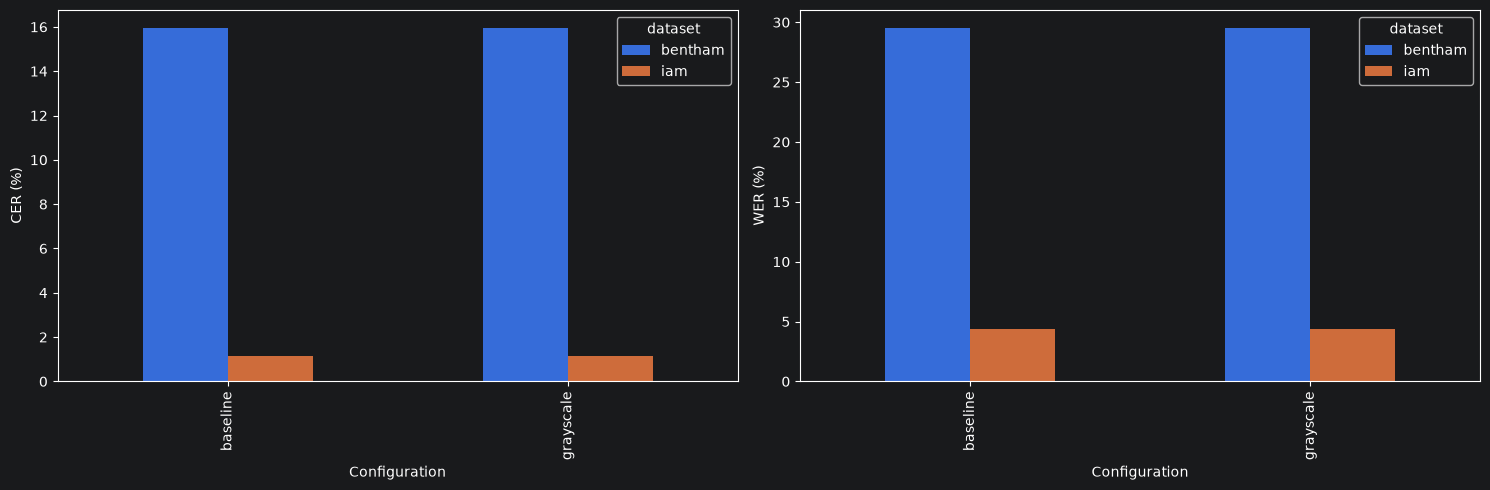

{
  "best_overall": "baseline",
  "best_grayscale": "grayscale",
  "grayscale_parameters": {
    "name": "grayscale",
    "enabled": true,
    "output_mode": "L"
  },
  "criterion": "lowest equal-dataset mean corpus CER; WER tie-breaker; baseline eligible",
  "dataset_winners": [
    {
      "dataset": "bentham",
      "configuration": "baseline",
      "cer": 0.15963923337091318,
      "wer": 0.2954796030871003
    },
    {
      "dataset": "iam",
      "configuration": "baseline",
      "cer": 0.011541072640868975,
      "wer": 0.0438034188034188
    }
  ]
}
Subset validation optimum; confirm on validation data before freezing final test parameters.


In [4]:
import pandas as pd
from src.validation.denoising import adapt_image
for index in range(len(iam)):
    original = adapt_image(iam[index]['image'])
    assert original.mode == 'L'
    assert configs['grayscale'](original).convert('RGB').tobytes() == original.convert('RGB').tobytes()
base_predictions = pd.read_csv(OUTPUT / 'iam/baseline/predictions.csv', keep_default_na=False)
gray_predictions = pd.read_csv(OUTPUT / 'iam/grayscale/predictions.csv', keep_default_na=False)
assert base_predictions[['sample_id', 'ground_truth', 'prediction']].equals(gray_predictions[['sample_id', 'ground_truth', 'prediction']])
print('IAM control passed: all 100 model-input images and predictions are identical.')
import matplotlib.pyplot as plt
assert len(table) == 4 and table.sample_count.eq(100).all()
fig, axes = plt.subplots(1, 2, figsize=(15, 5))
for ax, metric in zip(axes, ['cer', 'wer']):
    table.pivot(index='configuration', columns='dataset', values=metric).mul(100).plot.bar(ax=ax)
    ax.set_ylabel(metric.upper() + ' (%)')
    ax.set_xlabel('Configuration')
fig.tight_layout()
fig.savefig(OUTPUT / 'corpus_error_rates.png', dpi=160, bbox_inches='tight')
plt.show()
best_grayscale = ranking.drop(index='baseline').index[0]
selection = {'best_overall': ranking.index[0], 'best_grayscale': best_grayscale,
    'grayscale_parameters': configs[best_grayscale].to_config(),
    'criterion': metadata['selection'],
    'dataset_winners': winners[['dataset', 'configuration', 'cer', 'wer']].to_dict('records')}
(OUTPUT / 'selection.json').write_text(json.dumps(selection, indent=2))
(OUTPUT / 'status.json').write_text(json.dumps({'status': 'complete', 'grayscale_configurations': 1,
    'baseline_configurations': 1, 'validation_samples_per_dataset': 100,
    'completed_dataset_configuration_pairs': 4, 'seed': SEED}, indent=2))
print(json.dumps(selection, indent=2))
print('Subset validation optimum; confirm on validation data before freezing final test parameters.')